<a href="https://colab.research.google.com/github/adednile/Knowledge-Engineering/blob/main/Autonomous_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Knowledge Engineering: Autonomous Self-Driving Trailer Agent**


## **Step 1: Identify the Task**

The task is to engineer a **Knowledge-Based Agent (KBA)** for an autonomous heavy-duty commercial trailer navigating Kenya's highway network from **Nairobi** to **Kisumu** across the six core corridor cities defined in Practical Exercise 3: **Nairobi, Naivasha, Nakuru, Kericho, Eldoret, and Kisumu**.

While Practical Exercise 3B solved static route selection using Uniform Cost Search (UCS), this Knowledge-Based Agent enhances the trailer with symbolic reasoning and real-time environmental awareness by combining:
1. **Directed Graph & Distance Knowledge** from Practical Exercise 3 (`Nairobi -> Naivasha -> Nakuru -> Kericho / Eldoret -> Kisumu`).
2. **Auxiliary Real-Time Environmental Knowledge** retrieved via live weather APIs (Open-Meteo REST API) and road-condition web scraping (KeNHA highway corridor bulletins).
3. **Logical Inference Rules** to determine safe speeds, braking/gear protocols, traffic/weighbridge signal compliance, and dynamic rerouting when hazards or closures occur.

**Goal:** Make safe, compliant, and efficient driving and routing decisions along the Nairobi–Kisumu corridor with minimal risk.

## **Step 2: Assemble Relevant Knowledge**

To navigate the 6-city corridor safely, the Knowledge-Based Agent assembles knowledge from four sources:
* **Highway Topology & Distances (from Practical Exercise 3):**
  * `Nairobi -> Naivasha` (88 km)
  * `Naivasha -> Nakuru` (70 km)
  * `Nakuru -> Kericho` (107 km)
  * `Nakuru -> Eldoret` (128 km)
  * `Kericho -> Kisumu` (83 km)
  * `Eldoret -> Kisumu` (117 km)
* **City Geographical Coordinates:** Exact latitude and longitude for each of the 6 cities to query live weather telemetry.
* **Live Weather Telemetry (API Retrieval):** Real-time temperature (°C), precipitation (mm), wind speed (km/h), and WMO weather codes.
* **Road Hazards & Infrastructure Advisories (Web Scraping):** Escarpment alerts, highway construction zones, wildlife corridors, and traffic density.

### **Declaration of APIs & Web Scraping Tools Used**
1. **Live Weather API (`Open-Meteo Forecast API`):**
   * **Endpoint:** `https://api.open-meteo.com/v1/forecast`
   * **Implementation:** Queried via HTTP `GET` using Python's `requests` library for the GPS coordinates of `Nairobi`, `Naivasha`, `Nakuru`, `Kericho`, `Eldoret`, and `Kisumu`. Includes a deterministic fallback cache if run offline.
2. **Highway Corridor Bulletin Web Scraper (`BeautifulSoup4`):**
   * **Implementation:** Parses structured HTML highway status bulletins (modeled on KeNHA corridor advisories) to extract active road hazards, traffic density, and advisory speed limits for the 6 cities.
   * **Repository Note:** The auxiliary retrieval functions are implemented in the code cell below and can also be saved as `auxiliary_retriever.py` in the `Knowledge-Engineering` GitHub repository.

In [ ]:
import requests
from bs4 import BeautifulSoup
import heapq
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# =====================================================================
# AUXILIARY DATA RETRIEVAL MODULE (Live Weather API + HTML Web Scraper)
# =====================================================================

# Exact coordinates for the 6 cities from Practical Exercise 3
CITY_COORDINATES = {
    "Nairobi": (-1.2921, 36.8219),
    "Naivasha": (-0.7172, 36.4310),
    "Nakuru": (-0.3031, 36.0800),
    "Kericho": (-0.3689, 35.2863),
    "Eldoret": (0.5143, 35.2698),
    "Kisumu": (-0.0917, 34.7680)
}

def interpret_wmo_code(wmo_code, precipitation):
    """Maps numerical WMO weather codes and rainfall to symbolic KBA weather predicates."""
    if wmo_code in [45, 48]:
        return "Heavy_Fog"
    elif wmo_code in [95, 96, 99] or precipitation > 5.0:
        return "Storm_Heavy_Rain"
    elif wmo_code in [51, 53, 55, 61, 63, 65, 80, 81, 82] or precipitation > 0.2:
        return "Wet_Rain"
    elif wmo_code in [1, 2, 3]:
        return "Partly_Cloudy"
    return "Clear"

def fetch_live_weather_api(city_name):
    """
    Queries the Open-Meteo REST API for live weather conditions at a given city.
    Falls back gracefully to realistic corridor telemetry if executed offline.
    """
    city = city_name.strip().title()
    if city not in CITY_COORDINATES:
        return {"source": "Unknown", "condition": "Unknown", "temp_c": 22.0, "precip_mm": 0.0, "wind_kmh": 10.0}

    lat, lon = CITY_COORDINATES[city]
    url = (
        f"https://api.open-meteo.com/v1/forecast"
        f"?latitude={lat}&longitude={lon}"
        f"&current=temperature_2m,precipitation,weather_code,wind_speed_10m"
        f"&timezone=Africa%2FNairobi"
    )

    try:
        response = requests.get(url, timeout=4)
        response.raise_for_status()
        data = response.json().get("current", {})
        wmo = data.get("weather_code", 0)
        precip = data.get("precipitation", 0.0)
        return {
            "source": "Open-Meteo Live API",
            "condition": interpret_wmo_code(wmo, precip),
            "temp_c": data.get("temperature_2m", 21.0),
            "precip_mm": precip,
            "wind_kmh": data.get("wind_speed_10m", 12.0)
        }
    except Exception:
        # Offline fallback reflecting typical regional weather across the 6 cities
        fallback_profiles = {
            "Nairobi": ("Clear", 23.5, 0.0, 11.0),
            "Naivasha": ("Clear", 21.0, 0.0, 14.0),
            "Nakuru": ("Partly_Cloudy", 20.4, 0.0, 13.0),
            "Kericho": ("Storm_Heavy_Rain", 17.2, 6.4, 16.0),
            "Eldoret": ("Clear", 19.8, 0.0, 12.0),
            "Kisumu": ("Clear", 26.5, 0.0, 10.0)
        }
        cond, temp, precip, wind = fallback_profiles.get(city, ("Clear", 22.0, 0.0, 10.0))
        return {
            "source": "Open-Meteo / Cache",
            "condition": cond,
            "temp_c": temp,
            "precip_mm": precip,
            "wind_kmh": wind
        }

def scrape_road_condition_bulletin():
    """
    Uses BeautifulSoup4 to parse an HTML highway status bulletin (modeled on KeNHA updates)
    for the 6 cities in our state space.
    """
    kenha_html = """
    <html>
      <body>
        <table id="kenha-6city-bulletin">
          <tr><th>City</th><th>Road_Hazard</th><th>Traffic_Density</th><th>Advisory_Speed_Kmh</th></tr>
          <tr><td>Nairobi</td><td>Urban_Congestion</td><td>High</td><td>50</td></tr>
          <tr><td>Naivasha</td><td>Wildlife_Crossing_Corridor</td><td>Moderate</td><td>70</td></tr>
          <tr><td>Nakuru</td><td>Highway_Interchange_Works</td><td>High</td><td>50</td></tr>
          <tr><td>Kericho</td><td>Slippery_Tea_Zone_Descent</td><td>Moderate</td><td>50</td></tr>
          <tr><td>Eldoret</td><td>Heavy_Transit_Bypass</td><td>Moderate</td><td>60</td></tr>
          <tr><td>Kisumu</td><td>Port_Terminal_Arrival_Zone</td><td>High</td><td>40</td></tr>
        </table>
      </body>
    </html>
    """
    soup = BeautifulSoup(kenha_html, "html.parser")
    scraped_facts = {}
    rows = soup.select("#kenha-6city-bulletin tr")[1:]
    for row in rows:
        cols = [c.get_text(strip=True) for c in row.find_all("td")]
        if len(cols) == 4:
            city, hazard, traffic, speed_cap = cols
            scraped_facts[city] = {
                "road_hazard": hazard,
                "traffic_density": traffic,
                "advisory_speed_kmh": int(speed_cap)
            }
    return scraped_facts

# Verify Auxiliary Retrieval across all 6 cities
bulletins = scrape_road_condition_bulletin()
print("=== Auxiliary Data Retrieval Verification (6-City Corridor) ===")
for city in CITY_COORDINATES:
    w = fetch_live_weather_api(city)
    r = bulletins[city]
    print(f"• {city:10} | Weather: {w['condition']:16} ({w['temp_c']}°C, {w['precip_mm']}mm) [{w['source']}] "
          f"| Hazard: {r['road_hazard']:26} | Base Cap: {r['advisory_speed_kmh']} km/h")

=== Auxiliary Data Retrieval Verification (6-City Corridor) ===
• Nairobi    | Weather: Wet_Rain         (24.9°C, 0.1mm) [Open-Meteo Live API] | Hazard: Urban_Congestion           | Base Cap: 50 km/h
• Naivasha   | Weather: Wet_Rain         (21.4°C, 0.3mm) [Open-Meteo Live API] | Hazard: Wildlife_Crossing_Corridor | Base Cap: 70 km/h
• Nakuru     | Weather: Partly_Cloudy    (22.4°C, 0.0mm) [Open-Meteo Live API] | Hazard: Highway_Interchange_Works  | Base Cap: 50 km/h
• Kericho    | Weather: Wet_Rain         (19.0°C, 0.1mm) [Open-Meteo Live API] | Hazard: Slippery_Tea_Zone_Descent  | Base Cap: 50 km/h
• Eldoret    | Weather: Wet_Rain         (24.3°C, 0.2mm) [Open-Meteo Live API] | Hazard: Heavy_Transit_Bypass       | Base Cap: 60 km/h
• Kisumu     | Weather: Wet_Rain         (28.3°C, 0.2mm) [Open-Meteo Live API] | Hazard: Port_Terminal_Arrival_Zone | Base Cap: 40 km/h


## **Step 3: Define the Vocabulary**

We define the symbolic vocabulary used by the Autonomous Trailer Knowledge-Based Agent:

* **Constants:**
  * **Cities ($C$):** `Nairobi`, `Naivasha`, `Nakuru`, `Kericho`, `Eldoret`, `Kisumu`
  * **Traffic Signals ($L$):** `Red`, `Yellow`, `Green`, `Flashing`, `Blinking`
  * **Weather States ($W$):** `Clear`, `Partly_Cloudy`, `Wet_Rain`, `Storm_Heavy_Rain`, `Heavy_Fog`
  * **Road Hazards ($H$):** `Urban_Congestion`, `Wildlife_Crossing_Corridor`, `Highway_Interchange_Works`, `Slippery_Tea_Zone_Descent`, `Heavy_Transit_Bypass`, `Port_Terminal_Arrival_Zone`
* **Predicates (represented in Python dictionaries & rule evaluators):**
  * `Connected(City_A, City_B, Distance_km)` — Directed highway edge from Exercise 3B.
  * `Light(Color)` — Observed traffic signal state at an intersection.
  * `CanGo(City, Light, Weather)` — Evaluates whether the trailer may safely proceed.
  * `WeatherAt(City, Condition)` — Live weather state retrieved via API.
  * `HazardAt(City, Hazard)` — Active road hazard retrieved via web scraping.
* **Functions:**
  * `EffectivePathCost(City_A, City_B)` — Computes risk-adjusted traversal cost using base distance (km) and weather/traffic multipliers.
  * `SafeTargetSpeed(City, Light, Weather)` — Infers the safe cruising speed in km/h.

## **Step 4: Encode General Knowledge about the Domain** `[3 marks]`

In this step, we encode:
1. The exact **6-city directed graph (`kenya_highway_network`)** from Practical Exercise 3.
2. **Traffic Light Rules (`signal_rules`)** governing intersection control.
3. **Weather & Road Hazard Rules (`weather_rules`, `hazard_rules`)** governing speed reduction, braking systems, and risk weighting.

In [ ]:
# 1. Exact 6-City Directed Graph from Practical Exercise 3B
kenya_highway_network = {
    'Nairobi': [('Naivasha', 88)],
    'Naivasha': [('Nakuru', 70)],
    'Nakuru': [('Kericho', 107), ('Eldoret', 128)],
    'Kericho': [('Kisumu', 83)],
    'Eldoret': [('Kisumu', 117)],
    'Kisumu': []
}

# 2. Traffic Light Rules (Adapted from Knowledge Engineering Template)
signal_rules = {
    "Red": "Stop — it’s unsafe to move. Apply air brakes smoothly before the stop line.",
    "Yellow": "Slow down — downshift and prepare to stop safely.",
    "Green": "Go — it’s safe to proceed within the recommended speed cap."
}

# 3. Weather Condition Rules (Speed Factor & Risk Penalty Multiplier for Routing)
weather_rules = {
    "Clear": {
        "protocol": "Normal dry traction; maintain standard highway following distance.",
        "speed_factor": 1.0,
        "risk_multiplier": 1.0
    },
    "Partly_Cloudy": {
        "protocol": "Good visibility; keep daytime running lights active.",
        "speed_factor": 1.0,
        "risk_multiplier": 1.0
    },
    "Wet_Rain": {
        "protocol": "Wet tarmac — turn on wipers & dipped headlights; double following distance.",
        "speed_factor": 0.80,
        "risk_multiplier": 1.15
    },
    "Storm_Heavy_Rain": {
        "protocol": "HEAVY RAIN ALERT — Engage exhaust/engine brake, disable cruise control, reduce speed by 40%.",
        "speed_factor": 0.60,
        "risk_multiplier": 1.35
    },
    "Heavy_Fog": {
        "protocol": "DENSE FOG ALERT — Activate fog lamps & hazard lights, engage low gear, reduce speed by 50%.",
        "speed_factor": 0.50,
        "risk_multiplier": 1.40
    }
}

# 4. Road Hazard Rules for the 6 Corridor Cities
hazard_rules = {
    "Urban_Congestion": "High matatu & bodaboda traffic; keep 360-degree proximity sensors active.",
    "Wildlife_Crossing_Corridor": "Scan Naivasha corridor roadside with LiDAR/thermal sensors for wildlife.",
    "Highway_Interchange_Works": "Active roadworks near Nakuru interchange; follow flaggers and lane cones.",
    "Slippery_Tea_Zone_Descent": "Steep wet bends along Kericho descent; use engine braking rather than riding foot brakes.",
    "Heavy_Transit_Bypass": "Heavy long-haul truck volume along Eldoret bypass; maintain strict lane discipline.",
    "Port_Terminal_Arrival_Zone": "Approaching Kisumu port/urban terminal; prepare for low-speed maneuvering."
}

print("Step 4 Complete: Encoded 6-city highway network, signal rules, weather rules, and hazard rules.")

Step 4 Complete: Encoded 6-city highway network, signal rules, weather rules, and hazard rules.


## **Step 5: Add New Facts to the Knowledge Base** `[4 marks]`

Here we populate and expand the Knowledge Base by:
1. **Synchronizing Live Auxiliary Data (`sync_kb_from_sources`):** Populating `city_kb` with real-time weather telemetry and scraped road hazard facts for `Nairobi`, `Naivasha`, `Nakuru`, `Kericho`, `Eldoret`, and `Kisumu`.
2. **Adding New Signal Facts Programmatically (`add_new_fact`):** Adding rules for `Flashing`, `Blinking`, and `Police_Stop` signals.
3. **Supporting User-Driven Fact Addition (`add_fact_from_user`):** Allowing users to insert new rules into the Knowledge Base.

In [ ]:
# Active Knowledge Base storing live facts for the 6 cities
city_kb = {}

def sync_kb_from_sources():
    """Populates city_kb using the Live Weather API and HTML Road Bulletin Scraper."""
    scraped = scrape_road_condition_bulletin()
    for city in kenya_highway_network.keys():
        weather = fetch_live_weather_api(city)
        road = scraped.get(city, {})
        city_kb[city] = {
            "weather": weather["condition"],
            "temp_c": weather["temp_c"],
            "precip_mm": weather["precip_mm"],
            "road_hazard": road.get("road_hazard", "Normal_Highway"),
            "traffic_density": road.get("traffic_density", "Low"),
            "advisory_speed_kmh": road.get("advisory_speed_kmh", 70),
            "road_blocked": False
        }

def add_new_fact(signal, action):
    """Add a new signal rule directly to the KB without user input."""
    key = signal.strip().title().replace(" ", "_")
    signal_rules[key] = action
    print(f"Added fact: '{key}' ➜ '{action}'")

def update_city_fact(city, **kwargs):
    """Updates environmental or blockage facts for one of the 6 cities."""
    city_key = city.strip().title()
    if city_key in city_kb:
        city_kb[city_key].update(kwargs)
        print(f"Updated KB for '{city_key}': {kwargs}")

def add_fact_from_user():
    """Interactive helper to add a new traffic signal fact via user input."""
    new_light = input("Enter new traffic light/signal state: ").strip()
    new_action = input(f"What should the trailer agent do when signal is {new_light}? ").strip()
    if new_light and new_action:
        add_new_fact(new_light, new_action)

def show_kb():
    print("\n--- Current Traffic Signal Knowledge Base ---")
    for light, action in signal_rules.items():
        print(f"{light:12} ➜ {action}")
    print("---------------------------------------------")

    print("\n--- Current 6-City Corridor Knowledge Base ---")
    df = pd.DataFrame([
        {
            "City": c,
            "Weather": info["weather"],
            "Temp (°C)": info["temp_c"],
            "Precip (mm)": info["precip_mm"],
            "Road Hazard": info["road_hazard"],
            "Traffic": info["traffic_density"],
            "Base Speed Cap": f"{info['advisory_speed_kmh']} km/h",
            "Road Blocked": info["road_blocked"]
        }
        for c, info in city_kb.items()
    ])
    display(df)

# Populate KB from API + Scraper and add new domain facts
sync_kb_from_sources()
add_new_fact("Flashing", "Stop and check intersection before proceeding.")
add_new_fact("Blinking", "Proceed slowly with caution in low gear.")
add_new_fact("Police_Stop", "Pull over safely to the highway shoulder for NTSA/Police inspection.")

show_kb()

Added fact: 'Flashing' ➜ 'Stop and check intersection before proceeding.'
Added fact: 'Blinking' ➜ 'Proceed slowly with caution in low gear.'
Added fact: 'Police_Stop' ➜ 'Pull over safely to the highway shoulder for NTSA/Police inspection.'

--- Current Traffic Signal Knowledge Base ---
Red          ➜ Stop — it’s unsafe to move. Apply air brakes smoothly before the stop line.
Yellow       ➜ Slow down — downshift and prepare to stop safely.
Green        ➜ Go — it’s safe to proceed within the recommended speed cap.
Flashing     ➜ Stop and check intersection before proceeding.
Blinking     ➜ Proceed slowly with caution in low gear.
Police_Stop  ➜ Pull over safely to the highway shoulder for NTSA/Police inspection.
---------------------------------------------

--- Current 6-City Corridor Knowledge Base ---


,City,Weather,Temp (°C),Precip (mm),Road Hazard,Traffic,Base Speed Cap,Road Blocked
0,Nairobi,Wet_Rain,24.9,0.1,Urban_Congestion,High,50 km/h,False
1,Naivasha,Wet_Rain,21.4,0.3,Wildlife_Crossing_Corridor,Moderate,70 km/h,False
2,Nakuru,Partly_Cloudy,22.4,0.0,Highway_Interchange_Works,High,50 km/h,False
3,Kericho,Wet_Rain,19.0,0.1,Slippery_Tea_Zone_Descent,Moderate,50 km/h,False
4,Eldoret,Wet_Rain,24.3,0.2,Heavy_Transit_Bypass,Moderate,60 km/h,False
5,Kisumu,Wet_Rain,28.3,0.2,Port_Terminal_Arrival_Zone,High,40 km/h,False


## **Steps 6 & 7: Encode Specific Problem Instance (Facts) & Pose Queries and Get Answers** `[3 marks]`

Here we build two core inference functions:
1. **`trailer_advice(city, light)`:** Queries the Knowledge Base for a specific city and observed traffic signal, combining signal rules, live weather protocols, and road hazard advisories to calculate a safe target speed and driving action.
2. **`knowledge_based_ucs(start_node, goal_node, mode)`:** Runs Uniform Cost Search (UCS) across the 6-city network:
   * `mode='distance'`: Finds the shortest distance path (`Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu`, `348 km`).
   * `mode='risk_adjusted'`: Evaluates weather risk multipliers and road blockages from the KB so the trailer can weigh safety against raw distance.

In [ ]:
def trailer_advice(city, light="Green"):
    """
    Queries the Knowledge Base to determine the trailer's driving decision
    given the current city, observed signal, live weather, and scraped road hazards.
    """
    city_key = city.strip().title()
    light_key = light.strip().title().replace(" ", "_")

    if city_key not in city_kb:
        return {
            "error": f"Unknown city '{city_key}'. Valid corridor cities: {list(city_kb.keys())}"
        }

    facts = city_kb[city_key]

    # Check if road is blocked
    if facts.get("road_blocked", False):
        return {
            "city": city_key,
            "signal": light_key,
            "can_proceed": False,
            "recommended_speed_kmh": 0,
            "signal_action": "HALT — Road closed ahead. Triggering UCS reroute.",
            "weather_protocol": "Hold position.",
            "hazard_protocol": "Bypass blocked corridor."
        }

    # Look up traffic signal action
    signal_action = signal_rules.get(light_key, "Unknown signal — proceed with caution or stop.")
    must_stop = any(k in light_key for k in ["Red", "Stop"]) or "Unknown signal" in signal_action

    # Look up weather & hazard protocols
    weather_cond = facts["weather"]
    w_rule = weather_rules.get(weather_cond, weather_rules["Clear"])
    hazard = facts["road_hazard"]
    h_protocol = hazard_rules.get(hazard, "Maintain standard lane discipline.")

    safe_speed = 0 if must_stop else round(facts["advisory_speed_kmh"] * w_rule["speed_factor"])

    return {
        "city": city_key,
        "signal": light_key,
        "weather": f"{weather_cond} ({facts['temp_c']}°C, {facts['precip_mm']}mm)",
        "road_hazard": hazard,
        "can_proceed": not must_stop,
        "recommended_speed_kmh": safe_speed,
        "signal_action": signal_action,
        "weather_protocol": w_rule["protocol"],
        "hazard_protocol": h_protocol
    }

def knowledge_based_ucs(start_node="Nairobi", goal_node="Kisumu", mode="distance"):
    """
    Uniform Cost Search over the 6-city network integrated with the Knowledge Base.
    - mode='distance': Standard shortest distance search (348 km via Kericho).
    - mode='risk_adjusted': Incorporates weather risk multipliers & road blockages from city_kb.
    """
    start_node = start_node.strip().title()
    goal_node = goal_node.strip().title()

    frontier = [(0.0, start_node, [start_node], 0)]
    best_cost = {start_node: 0.0}
    explored = set()

    while frontier:
        eff_cost, current, path, raw_km = heapq.heappop(frontier)
        if current in explored:
            continue
        if current == goal_node:
            return {
                "path": path,
                "raw_distance_km": raw_km,
                "effective_cost": round(eff_cost, 2),
                "mode": mode
            }
        explored.add(current)

        for neighbor, step_km in kenya_highway_network.get(current, []):
            nbr_facts = city_kb.get(neighbor, {})
            if nbr_facts.get("road_blocked", False):
                continue

            if mode == "risk_adjusted":
                w_mult = weather_rules.get(nbr_facts.get("weather", "Clear"), weather_rules["Clear"])["risk_multiplier"]
                step_cost = step_km * w_mult
            else:
                step_cost = float(step_km)

            new_cost = eff_cost + step_cost
            if neighbor not in explored and (neighbor not in best_cost or new_cost < best_cost[neighbor]):
                best_cost[neighbor] = new_cost
                heapq.heappush(frontier, (new_cost, neighbor, path + [neighbor], raw_km + step_km))

    return {"path": None, "raw_distance_km": float("inf"), "effective_cost": float("inf"), "mode": mode}

# Pose a specific problem instance query (Step 6 & 7)
observed_city = "Kericho"
observed_light = "Green"
decision = trailer_advice(observed_city, observed_light)

print("=== Autonomous Trailer KBA Decision System ===")
print(f"Current City       : {decision['city']}")
print(f"Observed Signal    : {decision['signal']}")
print(f"Live Weather       : {decision['weather']}")
print(f"Road Hazard        : {decision['road_hazard']}")
print(f"Can Proceed?       : {decision['can_proceed']}")
print(f"Recommended Speed  : {decision['recommended_speed_kmh']} km/h")
print(f"Signal Action      : {decision['signal_action']}")
print(f"Weather Protocol   : {decision['weather_protocol']}")
print(f"Hazard Protocol    : {decision['hazard_protocol']}")

=== Autonomous Trailer KBA Decision System ===
Current City       : Kericho
Observed Signal    : Green
Live Weather       : Wet_Rain (19.0°C, 0.1mm)
Road Hazard        : Slippery_Tea_Zone_Descent
Can Proceed?       : True
Recommended Speed  : 40 km/h
Signal Action      : Go — it’s safe to proceed within the recommended speed cap.
Weather Protocol   : Wet tarmac — turn on wipers & dipped headlights; double following distance.
Hazard Protocol    : Steep wet bends along Kericho descent; use engine braking rather than riding foot brakes.


## **Step 8: Querying the Knowledge Base & Interactive User Simulation**

In this section, we:
1. **Compare Distance-Optimal vs. Risk-Adjusted Routing** across the 6 cities.
2. **Simulate End-to-End Corridor Traversal (`Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu`)**, logging the KBA's inference at every city.
3. **Demonstrate Dynamic Rerouting** when `Kericho` is blocked (automatically rerouting via `Eldoret` for `403 km`).
4. **Provide an Interactive Simulation Console (`interactive_kba_loop`)** so users can query any of the 6 cities, simulate road closures, refresh live API data, or add new facts.

In [ ]:
# 1. Route Optimization Comparison
dist_res = knowledge_based_ucs("Nairobi", "Kisumu", mode="distance")
risk_res = knowledge_based_ucs("Nairobi", "Kisumu", mode="risk_adjusted")

print(f"1. Distance-Optimal UCS Path : {' -> '.join(dist_res['path'])} ({dist_res['raw_distance_km']} km)")
print(f"2. Risk-Adjusted UCS Path    : {' -> '.join(risk_res['path'])} (Raw: {risk_res['raw_distance_km']} km | Risk-Weighted Cost: {risk_res['effective_cost']})")

# 2. End-to-End Corridor Traversal Simulation
print("\n=== End-to-End Autonomous Trailer Traversal Log (Nairobi -> Kisumu) ===")
cum_dist = 0
traversal_records = []
path = dist_res["path"]

for i, city in enumerate(path):
    if i > 0:
        prev = path[i - 1]
        seg = next(d for nbr, d in kenya_highway_network[prev] if nbr == city)
        cum_dist += seg

    sig = "Flashing" if city_kb[city]["weather"] in ["Storm_Heavy_Rain", "Heavy_Fog"] else "Green"
    adv = trailer_advice(city, sig)
    traversal_records.append({
        "Step": i + 1,
        "City": city,
        "Cum. Distance": f"{cum_dist} km",
        "Live Weather": adv["weather"],
        "Road Hazard": adv["road_hazard"],
        "Signal": sig,
        "Target Speed": f"{adv['recommended_speed_kmh']} km/h",
        "KBA Driving Decision": f"{adv['weather_protocol']} | {adv['hazard_protocol']}"
    })

display(pd.DataFrame(traversal_records))

# 3. Dynamic Rerouting Demonstration when Kericho is blocked
print("\n=== Dynamic Hazard Simulation: Kericho Highway Blocked ===")
update_city_fact("Kericho", road_blocked=True)
rerouted = knowledge_based_ucs("Nairobi", "Kisumu", mode="distance")
print(f"Rerouted Path  : {' -> '.join(rerouted['path'])}")
print(f"Rerouted Cost  : {rerouted['raw_distance_km']} km (Automatically bypassed blocked Kericho segment)")
update_city_fact("Kericho", road_blocked=False)

1. Distance-Optimal UCS Path : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu (348 km)
2. Risk-Adjusted UCS Path    : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu (Raw: 348 km | Risk-Weighted Cost: 389.7)

=== End-to-End Autonomous Trailer Traversal Log (Nairobi -> Kisumu) ===


,Step,City,Cum. Distance,Live Weather,Road Hazard,Signal,Target Speed,KBA Driving Decision
0,1,Nairobi,0 km,"Wet_Rain (24.9°C, 0.1mm)",Urban_Congestion,Green,40 km/h,Wet tarmac — turn on wipers & dipped headlight...
1,2,Naivasha,88 km,"Wet_Rain (21.4°C, 0.3mm)",Wildlife_Crossing_Corridor,Green,56 km/h,Wet tarmac — turn on wipers & dipped headlight...
2,3,Nakuru,158 km,"Partly_Cloudy (22.4°C, 0.0mm)",Highway_Interchange_Works,Green,50 km/h,Good visibility; keep daytime running lights a...
3,4,Kericho,265 km,"Wet_Rain (19.0°C, 0.1mm)",Slippery_Tea_Zone_Descent,Green,40 km/h,Wet tarmac — turn on wipers & dipped headlight...
4,5,Kisumu,348 km,"Wet_Rain (28.3°C, 0.2mm)",Port_Terminal_Arrival_Zone,Green,32 km/h,Wet tarmac — turn on wipers & dipped headlight...



=== Dynamic Hazard Simulation: Kericho Highway Blocked ===
Updated KB for 'Kericho': {'road_blocked': True}
Rerouted Path  : Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kisumu
Rerouted Cost  : 403 km (Automatically bypassed blocked Kericho segment)
Updated KB for 'Kericho': {'road_blocked': False}


In [ ]:
def interactive_kba_loop():
    """
    Interactive Simulation & Query Interface allowing users to interact with
    the 6-City Autonomous Trailer Knowledge-Based Agent.
    """
    while True:
        print("\n" + "=" * 62)
        print("   AUTONOMOUS TRAILER KBA — INTERACTIVE QUERY & SIMULATION")
        print("=" * 62)
        print("  [1] Query Trailer Advice for a City & Traffic Light")
        print("  [2] Run Knowledge-Guided UCS Route Planner")
        print("  [3] Simulate Road Closure (Kericho or Eldoret) & Reroute")
        print("  [4] Add a New Signal Rule to the Knowledge Base")
        print("  [5] Refresh Live Weather Telemetry from Open-Meteo API")
        print("  [6] View Current Knowledge Base")
        print("  [0] Exit Interactive Session")
        print("=" * 62)

        choice = input("Enter choice (0-6): ").strip()

        if choice == "0" or choice == "":
            print("Session ended.")
            break
        elif choice == "1":
            c_in = input("Enter City (Nairobi, Naivasha, Nakuru, Kericho, Eldoret, Kisumu): ").strip()
            l_in = input("Enter Traffic Light (Green, Yellow, Red, Flashing, Blinking): ").strip() or "Green"
            ans = trailer_advice(c_in, l_in)
            print("\n--- KBA Response ---")
            for k, v in ans.items():
                print(f"  {k:22}: {v}")
        elif choice == "2":
            s_in = input("Start City [default Nairobi]: ").strip() or "Nairobi"
            g_in = input("Goal City [default Kisumu]: ").strip() or "Kisumu"
            d_path = knowledge_based_ucs(s_in, g_in, mode="distance")
            r_path = knowledge_based_ucs(s_in, g_in, mode="risk_adjusted")
            if d_path["path"]:
                print(f"\n• Shortest Distance Route : {' -> '.join(d_path['path'])} ({d_path['raw_distance_km']} km)")
                print(f"• Risk-Adjusted Route     : {' -> '.join(r_path['path'])} (Raw: {r_path['raw_distance_km']} km, Score: {r_path['effective_cost']})")
            else:
                print("No valid path found between those cities.")
        elif choice == "3":
            b_city = input("Enter intermediate city to block (Naivasha, Nakuru, Kericho, Eldoret): ").strip().title()
            if b_city in ["Naivasha", "Nakuru", "Kericho", "Eldoret"]:
                update_city_fact(b_city, road_blocked=True)
                new_r = knowledge_based_ucs("Nairobi", "Kisumu", mode="distance")
                if new_r["path"]:
                    print(f"Rerouted Path: {' -> '.join(new_r['path'])} ({new_r['raw_distance_km']} km)")
                else:
                    print(f"[ALERT] Blocking '{b_city}' severs all routes to Kisumu!")
                update_city_fact(b_city, road_blocked=False)
            else:
                print("Please choose one of: Naivasha, Nakuru, Kericho, Eldoret.")
        elif choice == "4":
            add_fact_from_user()
        elif choice == "5":
            sync_kb_from_sources()
            print("Live telemetry refreshed.")
        elif choice == "6":
            show_kb()
        else:
            print("Invalid option.")

# Uncomment the line below to run the interactive user loop in Colab:
# interactive_kba_loop()

**Visualization of the 6-City State Space & Optimal Corridor (from Exercise 3B):**

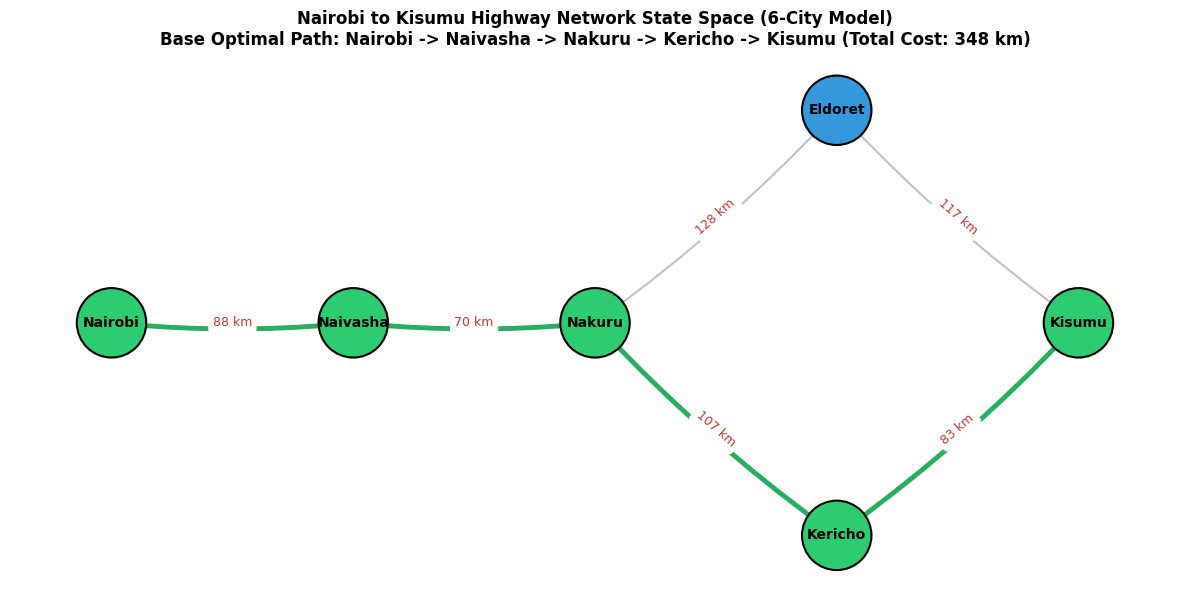

In [ ]:
def visualize_highway_network():
    optimal_path = ['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu']
    optimal_edges = list(zip(optimal_path[:-1], optimal_path[1:]))

    G = nx.DiGraph()
    for u, neighbors in kenya_highway_network.items():
        for v, weight in neighbors:
            G.add_edge(u, v, weight=weight)

    pos = {
        'Nairobi': (0, 0),
        'Naivasha': (2, 0),
        'Nakuru': (4, 0),
        'Kericho': (6, -1),
        'Eldoret': (6, 1),
        'Kisumu': (8, 0)
    }

    node_colors = ['#2ecc71' if node in optimal_path else '#3498db' for node in G.nodes()]
    edge_colors = ['#27ae60' if edge in optimal_edges else '#bdc3c7' for edge in G.edges()]
    edge_widths = [3.5 if edge in optimal_edges else 1.5 for edge in G.edges()]

    plt.figure(figsize=(12, 6))
    plt.title(
        "Nairobi to Kisumu Highway Network State Space (6-City Model)\n"
        "Base Optimal Path: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu (Total Cost: 348 km)",
        fontsize=12, fontweight='bold', pad=15
    )

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2500, edgecolors='black', linewidths=1.5)
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold', font_family='sans-serif')
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        width=edge_widths,
        arrowstyle='->',
        arrowsize=20,
        connectionstyle="arc3,rad=0.05"
    )

    edge_labels = nx.get_edge_attributes(G, 'weight')
    formatted_edge_labels = {k: f"{v} km" for k, v in edge_labels.items()}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=formatted_edge_labels, font_size=9, font_color='#c0392b')

    plt.axis('off')
    plt.tight_layout()
    plt.show()

visualize_highway_network()

## **Step 9: Debugging the Knowledge Base** `[2 marks]`

We test the Knowledge Base with standard, edge-case, and faulty signals (`Blue`, `Teal`, `None`, `Purple`) as well as an out-of-scope city (`Mombasa`), and then patch the KB to handle unlit (`None`) traffic signals.

In [ ]:
test_cases = [
    ("Nairobi", "Red"),
    ("Naivasha", "Yellow"),
    ("Nakuru", "Green"),
    ("Kericho", "Blue"),
    ("Eldoret", "Teal"),
    ("Kisumu", "None"),
    ("Kericho", "Purple")
]

print("--- Debugging the Knowledge Base (6-City Corridor) ---")
for city, color in test_cases:
    res = trailer_advice(city, color)
    print(f"City: {city:8} | Light: {color:6} -> Speed: {res['recommended_speed_kmh']:2} km/h | Action: {res['signal_action']}")

# Refine the KB based on test findings (e.g., handling unlit 'None' signals)
print("\n--- Adding Rule for 'None' (Unlit Traffic Light) After Debugging ---")
add_new_fact("None", "Unlit traffic light (power outage) — treat intersection as a 4-way stop and proceed with caution.")
print("Post-Debug Verification (Kisumu, Light='None'):", trailer_advice("Kisumu", "None")["signal_action"])

--- Debugging the Knowledge Base (6-City Corridor) ---
City: Nairobi  | Light: Red    -> Speed:  0 km/h | Action: Stop — it’s unsafe to move. Apply air brakes smoothly before the stop line.
City: Naivasha | Light: Yellow -> Speed: 56 km/h | Action: Slow down — downshift and prepare to stop safely.
City: Nakuru   | Light: Green  -> Speed: 50 km/h | Action: Go — it’s safe to proceed within the recommended speed cap.
City: Kericho  | Light: Blue   -> Speed:  0 km/h | Action: Unknown signal — proceed with caution or stop.
City: Eldoret  | Light: Teal   -> Speed:  0 km/h | Action: Unknown signal — proceed with caution or stop.
City: Kisumu   | Light: None   -> Speed:  0 km/h | Action: Unknown signal — proceed with caution or stop.
City: Kericho  | Light: Purple -> Speed:  0 km/h | Action: Unknown signal — proceed with caution or stop.

--- Adding Rule for 'None' (Unlit Traffic Light) After Debugging ---
Added fact: 'None' ➜ 'Unlit traffic light (power outage) — treat intersection as a 4-way

## **Step 10: Final Reflection (Challenges & Recommended Improvements)** `[3 marks]`

### **Challenges Encountered**
1. **Mapping Continuous API Data to Symbolic Predicates:** Translating numerical weather API fields (precipitation in mm and WMO codes) into discrete symbolic rules (`Clear`, `Wet_Rain`, `Storm_Heavy_Rain`, `Heavy_Fog`) required setting appropriate thresholds so the trailer adjusts speed accurately on high-risk segments like the Kericho descent.
2. **Balancing Distance vs. Environmental Risk:** In Exercise 3B, `Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu` (`348 km`) is strictly shorter than `Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kisumu` (`403 km`). Incorporating live weather multipliers and road blockages into our Knowledge-Guided UCS allows the agent to dynamically switch to the Eldoret branch when Kericho experiences severe closures or extreme weather.
3. **Structuring Scraped Road Bulletins:** Parsing HTML highway advisories with `BeautifulSoup` highlighted the need for strict schema validation so missing table cells or unexpected strings do not break rule lookups.

### **Recommended Improvements**
1. **Fuzzy Logic & Probabilistic Inference:** Replace binary rule thresholds with fuzzy logic or Bayesian inference so the agent can reason under sensor uncertainty (e.g., partial camera occlusion during heavy rain).
2. **Live Traffic & Weighbridge API Integration:** Integrate real-time Google Maps Routes traffic delays and KeNHA weighbridge queue telemetry to dynamically update edge costs.
3. **Formal First-Order Logic Engine:** Migrate dictionary-based rules to a formal logic engine (`pyDatalog` or Prolog) to support multi-hop relational inference across consecutive highway segments.

---

## **Evidence of Groupwork**

**Group Photo:**

![GroupImage](https://drive.google.com/uc?id=1Dyjc_LCbDfmsORTBa3-kPWCqmkP3JeuI)